In [ ]:
from pathlib import Path
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from attention_numpy import softmax, scaled_dot_product_attention, self_attention

np.set_printoptions(precision=6, suppress=True)
ROOT = Path.cwd()

## 1. Tính toán cơ bản

In [ ]:
q = np.array([1.0, 2.0])
K = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
scores_1 = K @ q
weights_1 = softmax(scores_1)

alpha = np.array([0.1, 0.2, 0.7])
V_3 = np.array([[1.0, 0.0], [0.0, 1.0], [2.0, 2.0]])
context_3 = alpha @ V_3

q_4 = np.array([[1.0, 0.0]])
K_4 = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
V_4 = np.array([[1.0, 0.0], [0.0, 2.0], [2.0, 1.0]])
scores_4, weights_4, context_4 = scaled_dot_product_attention(q_4, K_4, V_4)

calculation_table = pd.DataFrame({
    'Bài': ['Attention scores', 'Softmax weights', 'Context vector', 'Bài 4 scores', 'Bài 4 weights', 'Bài 4 context'],
    'Kết quả': [scores_1.tolist(), weights_1.tolist(), context_3.tolist(), scores_4[0].tolist(), weights_4[0].tolist(), context_4[0].tolist()]
})
calculation_table

,Bài,Kết quả
0,Attention scores,"[1.0, 2.0, 3.0]"
1,Softmax weights,"[0.09003057317038046, 0.24472847105479764, 0.6..."
2,Context vector,"[1.5, 1.5999999999999999]"
3,Bài 4 scores,"[0.7071067811865475, 0.0, 0.7071067811865475]"
4,Bài 4 weights,"[0.4011120926797859, 0.1977758146404282, 0.401..."
5,Bài 4 context,"[1.2033362780393577, 0.7966637219606423]"


## 2. Scaling và temperature

In [ ]:
raw_scores = np.array([4.0, 2.0, 0.0])
scaled_scores = raw_scores / np.sqrt(4)
scaling_table = pd.DataFrame([
    {'Trường hợp': 'Không scaling', 'Scores': raw_scores.tolist(), 'Weights': softmax(raw_scores).tolist()},
    {'Trường hợp': 'Chia sqrt(dk)', 'Scores': scaled_scores.tolist(), 'Weights': softmax(scaled_scores).tolist()}
])

base_scores = np.array([1.0, 2.0, 3.0])
temperature_rows = []
for temperature in [0.5, 1.0, 2.0]:
    weights = softmax(base_scores / temperature)
    entropy = -np.sum(weights * np.log(weights))
    temperature_rows.append({'Temperature': temperature, 'Max weight': weights.max(), 'Entropy': entropy, 'Weights': weights.tolist()})
temperature_table = pd.DataFrame(temperature_rows)
display(scaling_table)
display(temperature_table)

,Trường hợp,Scores,Weights
0,Không scaling,"[4.0, 2.0, 0.0]","[0.8668133321973347, 0.11731042782619835, 0.01..."
1,Chia sqrt(dk),"[2.0, 1.0, 0.0]","[0.6652409557748218, 0.24472847105479764, 0.09..."


,Temperature,Max weight,Entropy,Weights
0,0.5,0.866813,0.441057,"[0.015876239976466765, 0.11731042782619838, 0...."
1,1.0,0.665241,0.832396,"[0.09003057317038046, 0.24472847105479764, 0.6..."
2,2.0,0.506480,1.020191,"[0.1863237232258476, 0.3071958857184984, 0.506..."


## 3. Self-attention cho ba token

In [ ]:
tokens = ['I', 'like', 'cats']
X = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
WQ = np.eye(2)
WK = np.eye(2)
WV = np.eye(2)
Q, K, V, self_scores, self_weights, self_context = self_attention(X, WQ, WK, WV)

qkv_table = pd.DataFrame(Q, index=tokens, columns=['Q1', 'Q2'])
attention_table = pd.DataFrame(self_weights, index=tokens, columns=tokens)
context_table = pd.DataFrame(self_context, index=tokens, columns=['C1', 'C2'])
display(qkv_table)
display(attention_table)
display(context_table)

,Q1,Q2
I,1.0,0.0
like,0.0,1.0
cats,1.0,1.0


,I,like,cats
I,0.401112,0.197776,0.401112
like,0.197776,0.401112,0.401112
cats,0.248255,0.248255,0.503490


,C1,C2
I,0.802224,0.598888
like,0.598888,0.802224
cats,0.751745,0.751745


## 4. Embedding minh họa cho sentiment

In [ ]:
POS = {'good', 'great', 'excellent', 'fantastic', 'amazing', 'wonderful', 'love', 'like', 'enjoyable', 'brilliant', 'fun', 'engaging', 'compelling', 'moving', 'fresh', 'entertaining', 'recommend', 'best', 'beautiful', 'strong', 'impressive', 'surprisingly'}
NEG = {'bad', 'terrible', 'awful', 'boring', 'dull', 'disappointing', 'hate', 'dislike', 'poor', 'worst', 'slow', 'weak', 'messy', 'annoying', 'predictable', 'tedious', 'waste', 'confusing', 'forgettable', 'flat', 'unconvincing', 'painful'}
NEGATORS = {'not', 'never', 'no', 'hardly', "isn't", "wasn't", "don't", "didn't", "doesn't"}
INTENSIFIERS = {'very', 'really', 'extremely', 'absolutely', 'quite', 'so'}
CONTRAST = {'but', 'however', 'although', 'yet'}
NOUNS = {'cat', 'book', 'movie', 'film', 'acting', 'scene', 'story', 'plot', 'dialogue', 'ending', 'beginning', 'visuals', 'pacing', 'direction', 'character'}
VERBS = {'adopted', 'bought', 'sleeping', 'like', 'love', 'hate', 'dislike', 'enjoyed', 'thought', 'expected', 'got', 'works', 'improves', 'say'}
TIME_WORDS = {'yesterday', 'today', 'tomorrow', 'actually', 'later', 'first'}
ADJECTIVES = POS | NEG

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

def token_vector(token, polarity=0.0):
    vector = np.zeros(16, dtype=float)
    vector[0] = polarity
    vector[1] = float(token in POS)
    vector[2] = float(token in NEG)
    vector[3] = float(token in NEGATORS or token.endswith("n't"))
    vector[4] = float(token in INTENSIFIERS)
    vector[5] = float(token in CONTRAST)
    vector[6] = float(token in {'movie', 'film', 'acting', 'scene', 'story', 'plot', 'character', 'ending', 'beginning'})
    vector[7] = float(polarity != 0)
    vector[8] = float(token in NOUNS)
    vector[9] = float(token in VERBS)
    vector[10] = float(token in TIME_WORDS)
    vector[11] = float(token in ADJECTIVES)
    seed = int(hashlib.sha256(token.encode()).hexdigest()[:8], 16)
    vector[12:] = np.random.default_rng(seed).normal(0, 0.15, 4)
    return vector

def embed_text(text):
    tokens = tokenize(text)
    vectors = []
    for i, token in enumerate(tokens):
        polarity = 1.0 if token in POS else -1.0 if token in NEG else 0.0
        prior = tokens[max(0, i - 3):i]
        if polarity and any(word in NEGATORS or word.endswith("n't") for word in prior):
            polarity *= -1
        if polarity and any(word in INTENSIFIERS for word in tokens[max(0, i - 2):i]):
            polarity *= 1.35
        if polarity and any(word in CONTRAST for word in tokens[:i]):
            polarity *= 1.2
        vectors.append(token_vector(token, polarity))
    if not vectors:
        return np.zeros((1, 16), dtype=float)
    return np.vstack(vectors)

def attention_representation(text):
    X_text = embed_text(text)
    _, _, _, scores, weights, context = self_attention(X_text)
    return context.mean(axis=0), scores, weights, context

attention_representation('I like this movie.')[0]

array([ 0.313265,  0.313265,  0.      ,  0.      ,  0.      ,  0.      ,
        0.250885,  0.313265,  0.250885,  0.313265,  0.      ,  0.313265,
       -0.139071, -0.072585,  0.048641, -0.044786])

## 5. Huấn luyện classifier và đánh giá trên câu thử thách

In [ ]:
positive_adjectives = ['good', 'great', 'excellent', 'fantastic', 'amazing', 'wonderful', 'enjoyable', 'brilliant', 'fun', 'engaging', 'compelling', 'moving', 'fresh', 'entertaining', 'beautiful', 'impressive']
negative_adjectives = ['bad', 'terrible', 'awful', 'boring', 'dull', 'disappointing', 'poor', 'worst', 'slow', 'weak', 'messy', 'annoying', 'predictable', 'tedious', 'confusing', 'forgettable']
train_texts = []
train_labels = []
for adjective in positive_adjectives:
    for template in ['This movie was {a}.', 'The film is {a}.', 'I found the movie {a}.', 'The acting was {a}.']:
        train_texts.append(template.format(a=adjective))
        train_labels.append('positive')
for adjective in negative_adjectives:
    for template in ['This movie was {a}.', 'The film is {a}.', 'I found the movie {a}.', 'The acting was {a}.']:
        train_texts.append(template.format(a=adjective))
        train_labels.append('negative')
for adjective in positive_adjectives[:12]:
    train_texts.extend([f'I really enjoyed this {adjective} movie.', f'The final scene was {adjective}.'])
    train_labels.extend(['positive', 'positive'])
for adjective in negative_adjectives[:12]:
    train_texts.extend([f'I really disliked this {adjective} movie.', f'The final scene was {adjective}.'])
    train_labels.extend(['negative', 'negative'])

train_features = np.vstack([attention_representation(text)[0] for text in train_texts])
classifier = LogisticRegression(max_iter=1000, random_state=42)
classifier.fit(train_features, np.array(train_labels))

test_cases = [
    ('I like this movie.', 'positive', ''),
    ('I do not like this movie.', 'negative', ''),
    ('I thought this movie would be bad, but it was actually excellent.', 'positive', ''),
    ('The pacing is slow, but the ending is fantastic.', 'positive', ''),
    ('The film is not bad.', 'positive', ''),
    ('The acting is not good.', 'negative', ''),
    ('The movie is predictable but still enjoyable.', 'positive', ''),
    ('I love the visuals, yet the story is boring.', 'negative', 'ambiguous wording'),
    ('Great, another two hours wasted.', 'negative', 'sarcasm'),
    ('The plot was fine and the acting was poor.', 'negative', ''),
    ("I can't say it was good.", 'negative', 'negation'),
    ('This is sick!', 'positive', 'domain shift'),
    ('It is dull at first but improves a lot.', 'positive', 'long-range dependency'),
    ('Nothing about this movie works.', 'negative', 'negation'),
    ('Not only good but excellent.', 'positive', ''),
    ('The movie was so bad it became funny.', 'negative', 'ambiguous wording'),
    ('Despite a very slow beginning, the final scene was absolutely fantastic.', 'positive', 'long-range dependency'),
    ('The film is not terrible, but it is not enjoyable either.', 'negative', 'negation'),
    ('The direction is excellent, although the dialogue is awkward.', 'negative', 'ambiguous wording'),
    ('I expected a masterpiece and got a mess.', 'negative', 'ambiguous wording')
]

records = []
for number, (text, actual, error_category) in enumerate(test_cases, start=1):
    representation, score_matrix, weights, context = attention_representation(text)
    probabilities = classifier.predict_proba(representation.reshape(1, -1))[0]
    prediction = classifier.classes_[int(np.argmax(probabilities))]
    probability_map = dict(zip(classifier.classes_, probabilities))
    correct = prediction == actual
    records.append({
        'id': number,
        'text': text,
        'actual_label': actual,
        'predicted_label': prediction,
        'probability_negative': float(probability_map.get('negative', 0.0)),
        'probability_positive': float(probability_map.get('positive', 0.0)),
        'correct': bool(correct),
        'error_category': '' if correct else error_category or 'ambiguous wording'
    })

results = pd.DataFrame(records)
results.to_csv(ROOT / 'results.csv', index=False, float_format='%.6f')
display(results)
metrics = pd.DataFrame([{
    'n_test': len(results),
    'accuracy': accuracy_score(results['actual_label'], results['predicted_label']),
    'macro_precision': precision_recall_fscore_support(results['actual_label'], results['predicted_label'], labels=['negative', 'positive'], average='macro', zero_division=0)[0],
    'macro_recall': precision_recall_fscore_support(results['actual_label'], results['predicted_label'], labels=['negative', 'positive'], average='macro', zero_division=0)[1],
    'macro_f1': precision_recall_fscore_support(results['actual_label'], results['predicted_label'], labels=['negative', 'positive'], average='macro', zero_division=0)[2]
}])
metrics

,id,text,actual_label,predicted_label,probability_negative,probability_positive,correct,error_category
0,1,I like this movie.,positive,positive,0.072453,0.927547,True,
1,2,I do not like this movie.,negative,negative,0.612736,0.387264,True,
2,3,"I thought this movie would be bad, but it was ...",positive,positive,0.466679,0.533321,True,
3,4,"The pacing is slow, but the ending is fantastic.",positive,positive,0.464968,0.535032,True,
4,5,The film is not bad.,positive,positive,0.358423,0.641577,True,
5,6,The acting is not good.,negative,negative,0.649349,0.350651,True,
6,7,The movie is predictable but still enjoyable.,positive,positive,0.452996,0.547004,True,
7,8,"I love the visuals, yet the story is boring.",negative,negative,0.513589,0.486411,True,
8,9,"Great, another two hours wasted.",negative,positive,0.134932,0.865068,False,sarcasm
9,10,The plot was fine and the acting was poor.,negative,negative,0.727592,0.272408,True,


,n_test,accuracy,macro_precision,macro_recall,macro_f1
0,20,0.6,0.606061,0.606061,0.6


## 6. Confusion matrix

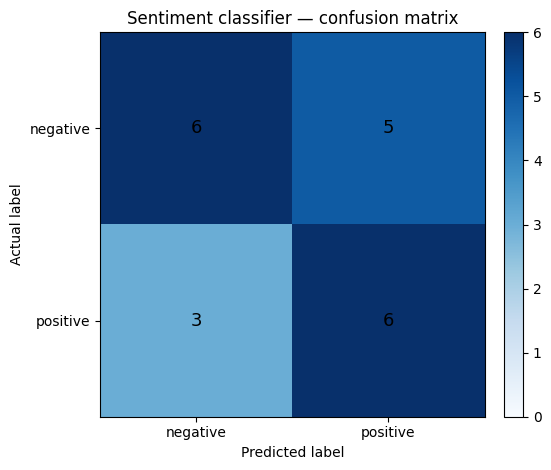

In [ ]:
label_order = ['negative', 'positive']
cm = confusion_matrix(results['actual_label'], results['predicted_label'], labels=label_order)
fig, ax = plt.subplots(figsize=(5.8, 4.8))
image = ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max())
ax.set_xticks(range(len(label_order)), labels=label_order)
ax.set_yticks(range(len(label_order)), labels=label_order)
ax.set_xlabel('Predicted label')
ax.set_ylabel('Actual label')
ax.set_title('Sentiment classifier — confusion matrix')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=13)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(ROOT / 'confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Attention heatmap

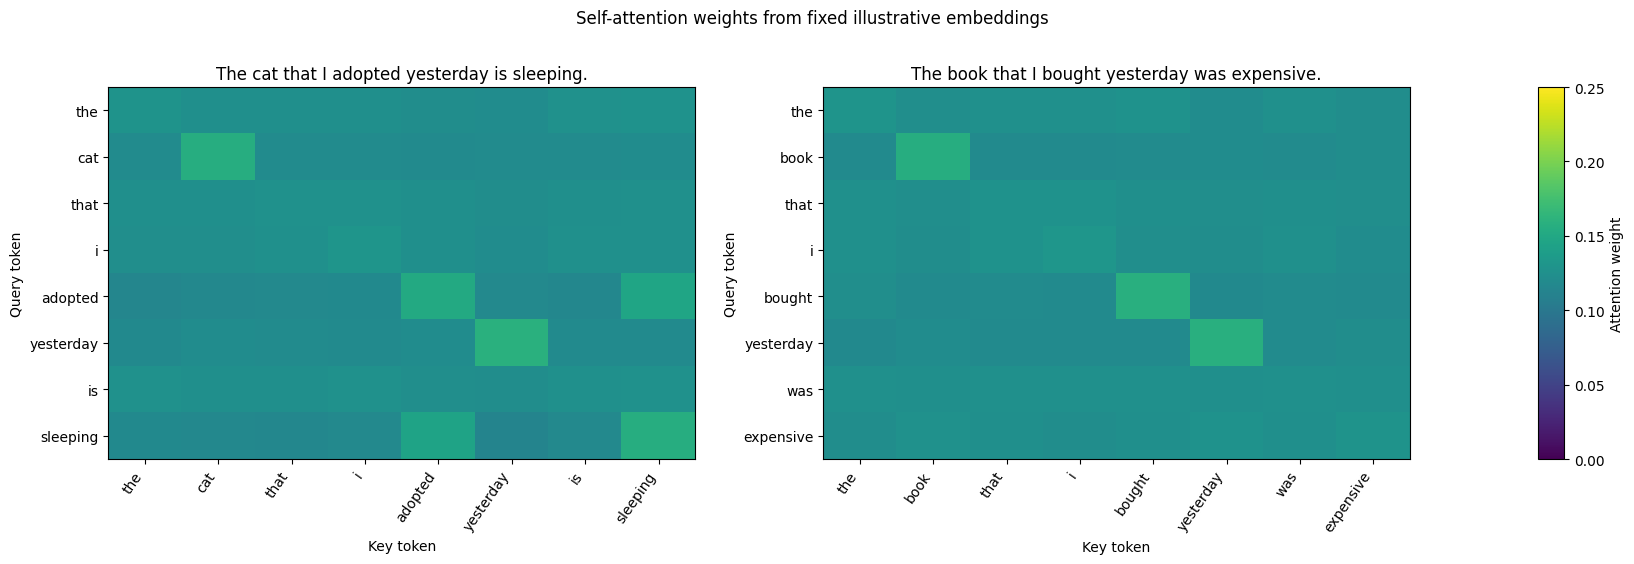

In [ ]:
sentences = [
    'The cat that I adopted yesterday is sleeping.',
    'The book that I bought yesterday was expensive.'
]
fig, axes = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1, 0.045]})
heat = None
for ax, sentence in zip(axes[:2], sentences):
    tokens = tokenize(sentence)
    X_sentence = embed_text(sentence)
    _, _, _, scores, weights, context = self_attention(X_sentence)
    heat = ax.imshow(weights, cmap='viridis', aspect='auto', vmin=0, vmax=0.25)
    ax.set_xticks(range(len(tokens)), labels=tokens, rotation=55, ha='right')
    ax.set_yticks(range(len(tokens)), labels=tokens)
    ax.set_xlabel('Key token')
    ax.set_ylabel('Query token')
    ax.set_title(sentence)
fig.colorbar(heat, cax=axes[2], label='Attention weight')
fig.suptitle('Self-attention weights from fixed illustrative embeddings', y=0.99)
fig.subplots_adjust(left=0.06, right=0.97, bottom=0.24, top=0.86, wspace=0.32)
fig.savefig(ROOT / 'attention_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

## 8. So sánh sequence length

In [ ]:
lengths = np.array([10, 100, 500, 1000, 10000], dtype=np.int64)
complexity_table = pd.DataFrame({
    'Sequence length': lengths,
    'Attention matrix': [f'{length:,} × {length:,}' for length in lengths],
    'Number of elements': lengths ** 2
})
complexity_table

,Sequence length,Attention matrix,Number of elements
0,10,10 × 10,100
1,100,100 × 100,10000
2,500,500 × 500,250000
3,1000,"1,000 × 1,000",1000000
4,10000,"10,000 × 10,000",100000000


## 9. Ba ví dụ sentiment trong đề

In [ ]:
lab_examples = [
    ('I like this movie.', 'positive'),
    ('I do not like this movie.', 'negative'),
    ('I thought this movie would be bad, but it was actually excellent.', 'positive')
]
example_rows = []
for text, expected_label in lab_examples:
    representation, score_matrix, weights, context = attention_representation(text)
    probabilities = classifier.predict_proba(representation.reshape(1, -1))[0]
    prediction = classifier.classes_[int(np.argmax(probabilities))]
    probability_map = dict(zip(classifier.classes_, probabilities))
    example_rows.append({
        'text': text,
        'expected_label': expected_label,
        'prediction': prediction,
        'probability_positive': probability_map.get('positive', 0.0),
        'attention_weights': weights.mean(axis=0).round(4).tolist()
    })
pd.DataFrame(example_rows)

,text,expected_label,prediction,probability_positive,attention_weights
0,I like this movie.,positive,positive,0.927547,"[0.2197, 0.3133, 0.2161, 0.2509]"
1,I do not like this movie.,negative,negative,0.387264,"[0.1559, 0.1555, 0.1617, 0.2032, 0.1536, 0.1701]"
2,"I thought this movie would be bad, but it was ...",positive,positive,0.533321,"[0.0804, 0.0826, 0.0803, 0.0847, 0.0805, 0.080..."
